# 04 · Pregunta 2b: afinidades entre géneros

**Responsable:** Integrante D · **Plan:** ver `PLAN.md`

¿Qué géneros tienden a gustar juntos, más allá de que se asignen juntos a las mismas películas?

## Preparación

In [10]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Busca la raíz del repo (la carpeta que contiene src/) sin importar desde dónde se abra el notebook.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))


sns.set_theme(style="whitegrid")  # estilo común para todas las figuras del proyecto

from src import contratos, rutas
from src import limpieza, afinidades_generos


## Datos

In [11]:
movies, ratings = limpieza.datos_limpios()
contratos.verificar_esquema(movies, "movies")
contratos.verificar_esquema(ratings, "ratings")
print(movies.shape, ratings.shape)

(9742, 23) (100836, 5)


## 1. Panorama por género

In [12]:
#Agrupamos ratings por movieId y calculamos el número de ratings y la media de los ratings por película
rating_por_pelicula=ratings.groupby('movieId').agg(n_ratings=("rating", "count"), media_rating=("rating", "mean")).reset_index()

#obtenemos la lista de géneros únicos en el dataset de movies
print(movies.columns.tolist())
col_gen=['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

#hacemos el cruce de tablas
tabla_completa=pd.merge(movies[['movieId']+col_gen], rating_por_pelicula, on='movieId', how='left')

#usamos melt para convertir las columnas de géneros en filas
tabla_conv=tabla_completa.melt(
    id_vars=['movieId' ,'n_ratings','media_rating'],
    value_vars=col_gen,
    var_name='genres',
    value_name='has_genre'
)

#Nos quedamos solo la s filas donde has_genre es 1 (es decir, la película pertenece a ese género)
tabla_conv=tabla_conv[tabla_conv['has_genre']==1]

#obtenemos la tabla resumen por género
tabla_resumen=tabla_conv.groupby('genres').agg(n_peliculas=("movieId", "count"),n_ratingsT=("n_ratings", "sum"),mean_rating=("media_rating", "mean"),median_rating=("media_rating", "median"), std_rating=("media_rating", "std") ).reset_index()
display(tabla_resumen)

['movieId', 'title', 'anio', 'n_generos', 'es_imax', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


,genres,n_peliculas,n_ratingsT,mean_rating,median_rating,std_rating
0,Action,1828,30635.0,3.094498,3.200000,0.838268
1,Adventure,1263,24161.0,3.215230,3.333333,0.792274
2,Animation,611,6988.0,3.497119,3.531751,0.902377
3,Children,664,9208.0,3.107690,3.174242,0.907741
4,Comedy,3756,39053.0,3.181716,3.250000,0.883640
5,Crime,1199,16681.0,3.301844,3.456439,0.819136
6,Documentary,440,1219.0,3.781682,4.000000,0.711097
7,Drama,4361,41928.0,3.420905,3.500000,0.781122
8,Fantasy,779,11834.0,3.218843,3.352419,0.876802
9,Film-Noir,87,870.0,3.670471,3.812500,0.657428


WindowsPath('C:/Users/Andres Sanchez/OneDrive - Multilog Internacional S.A de C.V/Documents/Scripts/movielens-proyecto-integrador/results/figures/04_boxplot_generos.png')

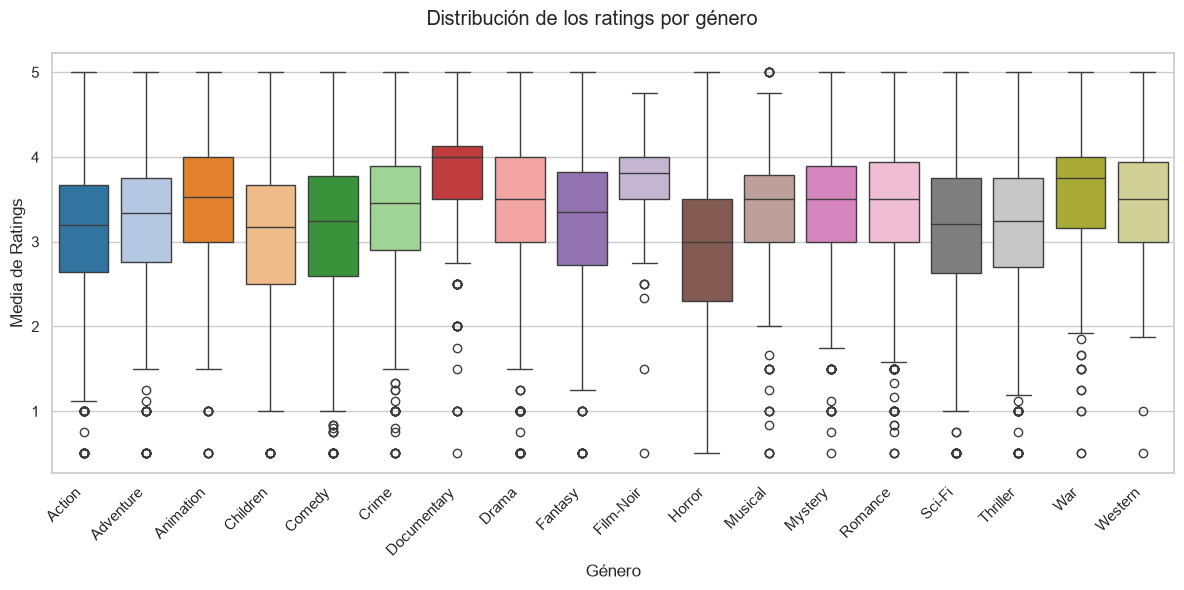

In [13]:
# rutas.guardar_figura(fig, "04_boxplot_generos")
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(x='genres', y='media_rating', hue='genres', palette="tab20", data=tabla_conv)
fig.suptitle('Distribución de los ratings por género')
plt.xlabel('Género', fontsize=12)
plt.ylabel('Media de Ratings', fontsize=12)
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
rutas.guardar_figura(fig, "04_boxplot_generos")

> **Interpretación**
> - *Qué muestra:* Las cajas nos describen los ratings por género, por lo que podemos ver que ciertas cajas son más estrechas que otras por lo que decimos que hay un mayo conceso en cuanto a la calificación de esos géneros. Por otro lado las cajas más alargadas nos hablan de género con recepción mixta.  
> - *Por qué es relevante:* Podemos ver géneros que tienen universos más grandes que otros, lo que se traduce en que son géneros más vistos y a su vez podemos observar géneros de nicho que a pesar de su bajo número de reseñas su rating se concentra alto.
> - *Limitaciones:* Observamos que hay datos atipicos en todas las categorias pero son calificaciones bajas lo que nos puede hablar de los bajos criterios que los usuarios usaron para asignarles un rating. 

## 2. Coocurrencia de géneros

Correlación entre las 18 columnas 0/1 de `movies`.

,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
Action,1.00,0.29,0.03,-0.05,-0.15,0.15,-0.10,-0.15,0.06,-0.03,-0.04,-0.08,-0.03,-0.15,0.23,0.20,0.08,0.02
Adventure,0.29,1.00,0.21,0.27,-0.06,-0.09,-0.08,-0.16,0.26,-0.03,-0.10,-0.01,-0.05,-0.07,0.18,-0.04,0.01,0.04
Animation,0.03,0.21,1.00,0.44,0.03,-0.07,-0.05,-0.16,0.20,-0.02,-0.06,0.11,-0.03,-0.06,0.06,-0.11,-0.04,-0.02
Children,-0.05,0.27,0.44,1.00,0.09,-0.09,-0.06,-0.16,0.23,-0.03,-0.08,0.14,-0.04,-0.07,-0.01,-0.13,-0.05,-0.02
Comedy,-0.15,-0.06,0.03,0.09,1.00,-0.08,-0.13,-0.28,-0.01,-0.07,-0.13,0.05,-0.13,0.15,-0.13,-0.29,-0.10,-0.04
Crime,0.15,-0.09,-0.07,-0.09,-0.08,1.00,-0.07,0.06,-0.09,0.14,-0.06,-0.06,0.12,-0.10,-0.10,0.27,-0.06,-0.02
Documentary,-0.10,-0.08,-0.05,-0.06,-0.13,-0.07,1.00,-0.17,-0.06,-0.02,-0.07,-0.01,-0.05,-0.09,-0.07,-0.10,-0.01,-0.02
Drama,-0.15,-0.16,-0.16,-0.16,-0.28,0.06,-0.17,1.00,-0.11,0.02,-0.19,-0.04,0.03,0.12,-0.16,-0.01,0.14,-0.03
Fantasy,0.06,0.26,0.20,0.23,-0.01,-0.09,-0.06,-0.11,1.00,-0.02,0.01,0.05,0.01,-0.00,0.05,-0.06,-0.04,-0.02
Film-Noir,-0.03,-0.03,-0.02,-0.03,-0.07,0.14,-0.02,0.02,-0.02,1.00,-0.02,-0.02,0.09,-0.02,-0.02,0.07,-0.02,-0.00


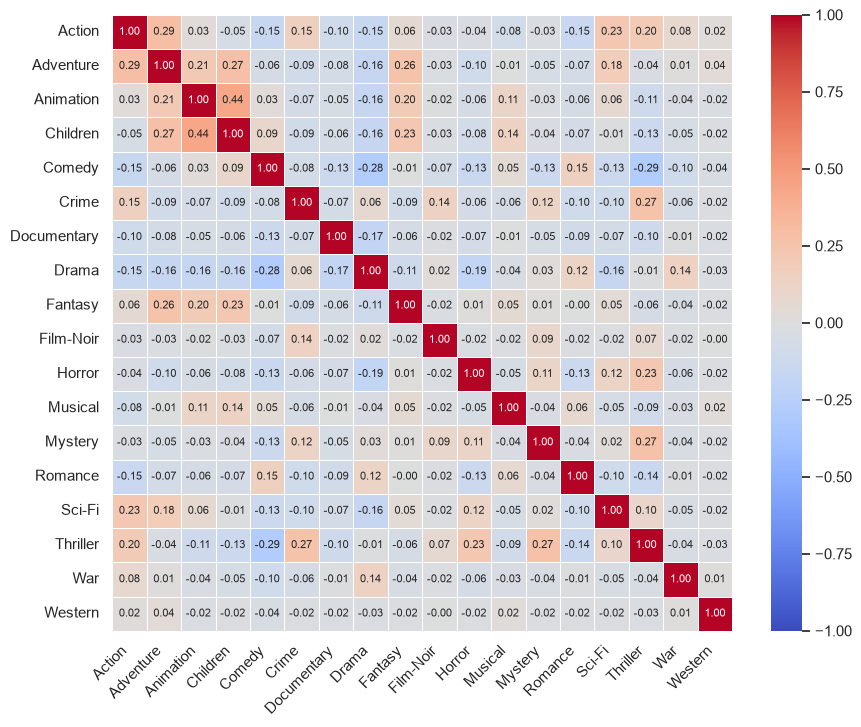

In [ ]:
matriz_corr=movies[col_gen].corr()
display(matriz_corr.round(2))
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, annot_kws={'size': 8}, fmt='.2f', cmap='coolwarm',vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.xticks(rotation=45, ha='right')
plt.show()

## 3. Preferencias por género

In [15]:
perfil = afinidades_generos.perfil_genero(ratings, movies, min_r=5)
contratos.verificar_matriz(perfil, "proporcion", contratos.GENEROS)
perfil.shape

(610, 18)

,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
Action,1.00,0.85,0.63,0.62,0.71,0.72,0.58,0.70,0.69,0.62,0.68,0.60,0.73,0.66,0.85,0.84,0.67,0.75
Adventure,0.85,1.00,0.79,0.77,0.74,0.63,0.61,0.70,0.80,0.68,0.60,0.70,0.65,0.69,0.80,0.72,0.63,0.76
Animation,0.63,0.79,1.00,0.91,0.79,0.60,0.62,0.72,0.82,0.63,0.54,0.82,0.58,0.73,0.63,0.62,0.61,0.70
Children,0.62,0.77,0.91,1.00,0.77,0.58,0.48,0.69,0.82,0.51,0.51,0.81,0.54,0.69,0.61,0.61,0.56,0.70
Comedy,0.71,0.74,0.79,0.77,1.00,0.75,0.73,0.77,0.76,0.76,0.60,0.73,0.69,0.83,0.65,0.68,0.67,0.76
Crime,0.72,0.63,0.60,0.58,0.75,1.00,0.63,0.81,0.61,0.79,0.64,0.63,0.76,0.68,0.61,0.82,0.71,0.72
Documentary,0.58,0.61,0.62,0.48,0.73,0.63,1.00,0.63,0.57,NaN,0.54,0.60,0.61,0.69,0.56,0.64,0.51,0.52
Drama,0.70,0.70,0.72,0.69,0.77,0.81,0.63,1.00,0.70,0.81,0.63,0.73,0.81,0.84,0.64,0.79,0.78,0.75
Fantasy,0.69,0.80,0.82,0.82,0.76,0.61,0.57,0.70,1.00,0.69,0.59,0.78,0.62,0.70,0.63,0.64,0.60,0.72
Film-Noir,0.62,0.68,0.63,0.51,0.76,0.79,NaN,0.81,0.69,1.00,0.62,0.57,0.75,0.67,0.59,0.72,0.67,0.66


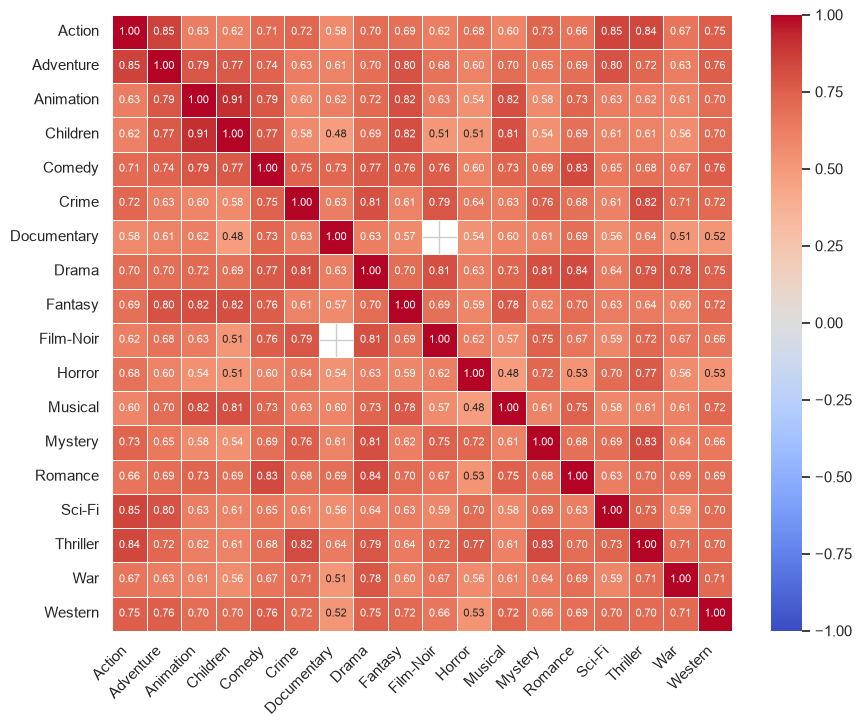

In [ ]:
matriz_corr_pref = perfil.corr(min_periods=30)
display(matriz_corr_pref.round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr_pref, annot=True, annot_kws={'size': 8}, fmt='.2f', cmap='coolwarm',vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.xticks(rotation=45, ha='right')
plt.show()

## 4. Preferencia vs. coocurrencia

C:\Users\chiva\AppData\Local\Temp\ipykernel_25736\2318881499.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


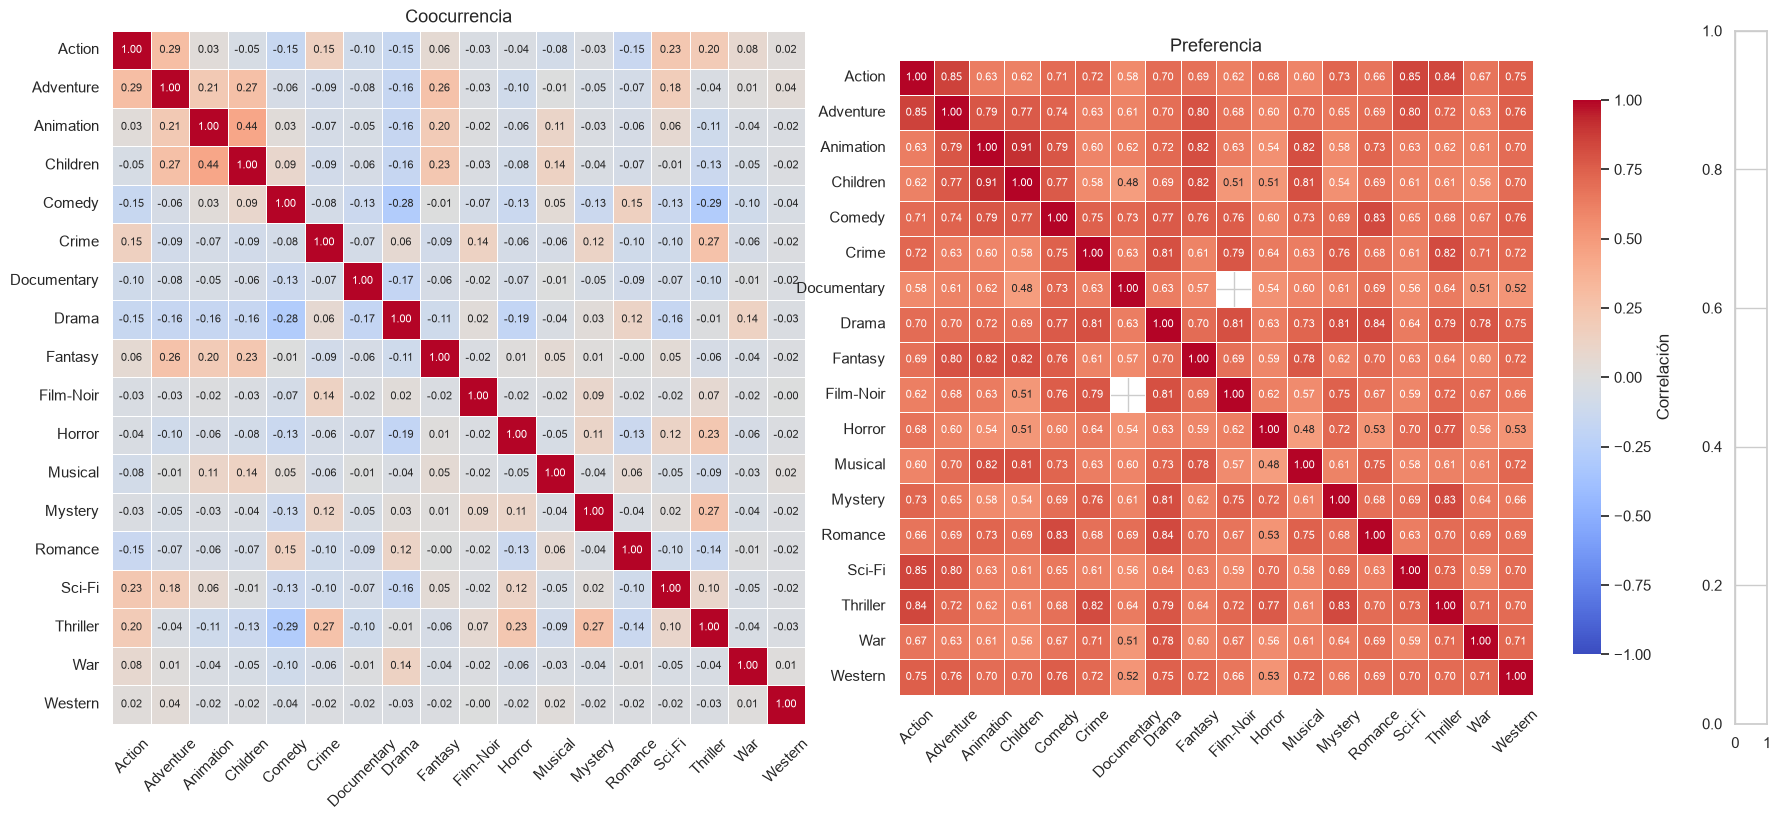

In [ ]:
# rutas.guardar_figura(fig, "04_heatmaps_generos")
vmin, vmax = -1.0, 1.0
fig, (ax1, ax2, cbar_ax) = plt.subplots(1,3,figsize=(22, 9),gridspec_kw={"width_ratios": [1, 1, 0.04], "wspace": 0.08},)
sns.heatmap(
    matriz_corr,
    ax=ax1,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    center=0,
    square=True,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.5,
    cbar=False,  
)
ax1.set_title("Coocurrencia", fontsize=13)
ax1.tick_params(axis="x", rotation=45)
ax1.tick_params(axis="y", rotation=0)

# --- Heatmap Derecho (axes) ---
sns.heatmap(
    matriz_corr_pref,
    ax=ax2,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    center=0,
    square=True,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.5,
    cbar=cbar_ax,
    cbar_kws={"label": "Correlación", "shrink": 0.8},
)
ax2.set_title("Preferencia", fontsize=13)
ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()

rutas.guardar_figura(fig, "04_heatmaps_generos")
plt.show()

> **Interpretación**
> - *Qué muestra:* Podemos ver algunas correlaciones fuertes para parejas de género (gráfica izquierda), lo que quiere decir que hay géneros que por naturaleza van bien juntos por ejemplo Thriller-Misterio o Niños-Animación. Mientras que en la otra gráfica tenemos todas las combinaciones con una fuerte correlación a excepción que de la pareja Documental-Film-Noir lo que nos puede decir que no hay suficientes observaciones que combinen estos géneros. 
> - *Por qué es relevante:* El género no impide que el espectador pueda disfrutar de otro género (como se muestra en la gráfica derecha) las correlaciones de gustos son altas para todo par de géneros.
> - *Limitaciones:* El heatmap de afinidad por género tiene correlaciones altas, lo que nos confirma las sospechas que teníamos en el boxplot de qu elos usuarios que dieron ratings usuaron criterios laxos (están sesgadas hacias calificaciones altas).

C:\Users\Andres Sanchez\AppData\Local\Temp\ipykernel_48216\3636710918.py:46: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper left")


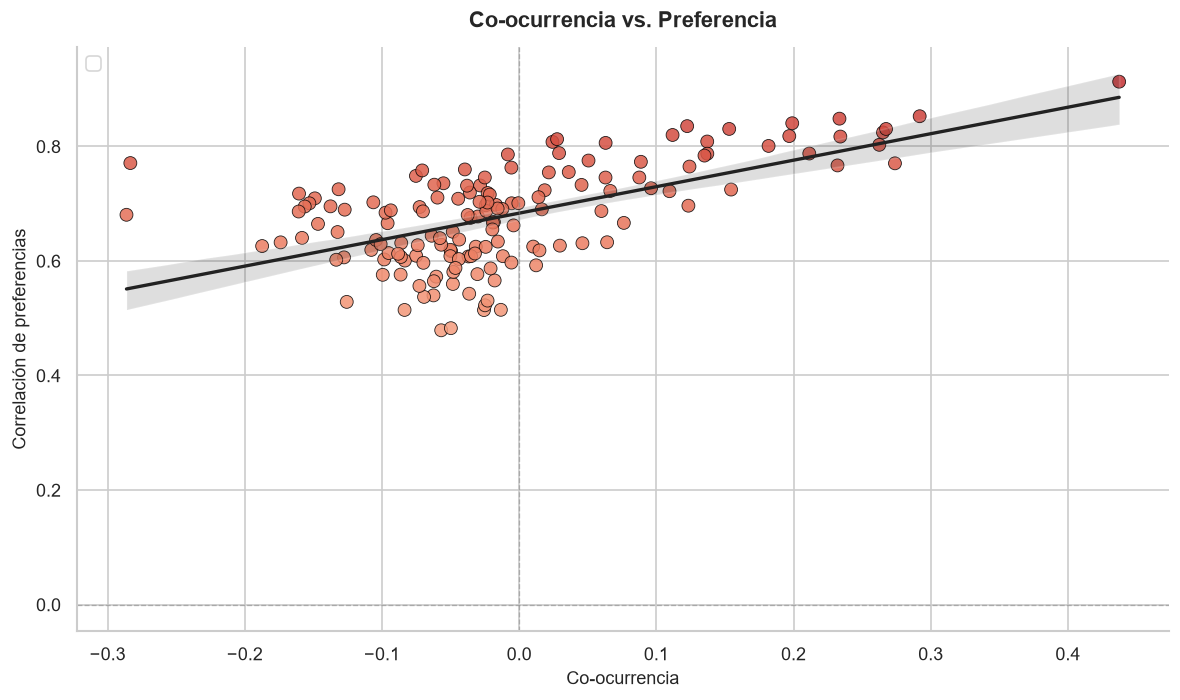

In [14]:
# rutas.guardar_figura(fig, "04_scatter_pares")

mask = np.triu(np.ones(matriz_corr.shape, dtype=bool), k=1)

df_pares = pd.DataFrame({
    "coocurrencia": matriz_corr.where(mask).stack(),
    "preferencia": matriz_corr_pref.where(mask).stack(),
}).dropna()

fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

#Puntos coloreados según el valor de preferencia (coolwarm: rojo a azul)
sc = ax.scatter(
    df_pares["coocurrencia"],
    df_pares["preferencia"],
    c=df_pares["preferencia"],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    s=60,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.5,
)

# Línea de tendencia encima sin duplicar los puntos
sns.regplot(
    data=df_pares,
    x="coocurrencia",
    y="preferencia",
    scatter=False,
    ax=ax,
    line_kws={"color": "#222222", "linewidth": 2, "label": "Tendencia lineal"},
)


ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
sns.despine(top=True, right=True)

ax.set_title(
    "Co-ocurrencia vs. Preferencia", fontsize=13, fontweight="bold", pad=12
)
ax.set_xlabel("Co-ocurrencia", fontsize=11)
ax.set_ylabel("Correlación de preferencias", fontsize=11)
ax.legend(loc="upper left")

plt.tight_layout()
rutas.guardar_figura(fig, "04_scatter_pares")
plt.show()

> **Interpretación**
> - *Qué muestra:* El gráfico muestra una tendencia positiva en la preferencia del público cuando más de un género aparecen juntos. Esto puede ser esperado ya que al agregar más géneros estas complaciendo los justos de más personas.
> - *Por qué es relevante:* Gracias a esta gráfica podemos obeservar que no hay géneros de nichos en nuestra base de datos, es decir, quienes disfrutan más un género puede disfrutar otro sin problemas.
> - *Limitaciones:* Los criterios de calificación de los usuarios pueden ser muy laxos, lo que puede hacer que a todo le den una buena calificación de ahí se explicaría las correlaciones superiores a $0.48$. 

## 5. Conclusión y limitaciones

Podemos concluir que de acuerdo a nuestra base la afinidad por un género no esta restringida a nichos lo que hace que las califiaciones sean consistentes en todos los géneros. También podemos ver que hay generos que tienen un número de reseñas muy superiores respecto a otros, lo que sugeriría el uso de pesos que lo ponderen. Otra limitante es que las opiniones de los usuarios esten sesgadas por gustos personales o experiencias vividas que hayan influido en el rating que se les otorgó. Finalmente si bien las gráficas muestran patrones en preferencias no implica que cierto género obtenga más dinero en taquilla o venta/renta de péliculas, cuyo caso se necesitaria más información.
